# Benchmark: wages and their spread in the CPS 1988

Twelve models of log hourly wages for 28,155 men in the March 1988 Current Population Survey {cite:p}`bierens2001integrated,kleiber2008applied`, scored on held-out rows over 3 shared 80/20 splits. The mean of log wages is a textbook Mincer regression. The spread is not constant: part-time workers' wages are much more dispersed than full-time workers', and dispersion grows late in a career. The comparison measures how modelling the standard deviation changes predictive log scores and interval coverage relative to mean-only models.

Every method is scored as a Gaussian predictive distribution on the log scale, with its own mean and standard deviation. Mean-only methods use one standard deviation for everyone, the training residual SD.

This page reads a recorded artifact and refits nothing.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | how twelve predictive distributions for log wages score on held-out CPS 1988 men |
| **Observed response** | log hourly wage |
| **Estimand** | mean held-out Gaussian negative log predictive density (log score), with CRPS, RMSE and 90% interval coverage, overall and for part-time workers |
| **Units** | nats per held-out man (log score); log dollars (CRPS, RMSE); proportions (coverage) |
| **Sampling unit** | one man in the March 1988 CPS |
| **Dependence** | treated as independent across men |
| **Split / resampling unit** | the man; the same 3 random 80/20 splits for every method |
| **Tuning** | `tune_mstop` (5-fold CV) for mboostrs, a mapping specification for GaussianLSS; `gridsearch` for pyGAM; 400 rounds at learning rate 0.05 for the trees, plus a LightGBM arm with rounds chosen by 5-fold CV early stopping |
| **Uncertainty** | across-split standard errors (only 3 splits, but each holds 5,600 rows) and paired per-split differences |
| **Claim type** | predictive comparison of distributional fit under the stated protocol; not an estimate of wage inequality |
:::

In [1]:
from IPython.display import display
import altair as alt
import numpy as np
import polars as pl

from public_tasks import (
    failures, lines, load, memory, paired, protocol, summary, table, warnings_by_method,
)

bench, runs = load("distributional")
display(table(
    protocol(bench), stub="item", stubhead="Item",
    title="What was run", subtitle="Pinned source, shared splits, one thread per library",
    notes=["Source: bench_public_distributional.json, written by benches/bench_public_tasks.py."],
))

GT(_tbl_data=shape: (11, 2)
┌───────────────────────┬─────────────────────────────────┐
│ item                  ┆ value                           │
│ ---                   ┆ ---                             │
│ str                   ┆ str                             │
╞═══════════════════════╪═════════════════════════════════╡
│ source                ┆ https://raw.githubusercontent.… │
│ source sha256         ┆ ef5ee9cbf3674f9c…               │
│ train fraction        ┆ 0.8                             │
│ seeds (random splits) ┆ 3                               │
│ trees (fixed setting) ┆ 400 rounds, learning rate 0.05  │
│ …                     ┆ …                               │
│ versions              ┆ mboostrs 0.1.3, polars 2.0.0, … │
│ commit                ┆ 836c450c8c + uncommitted runne… │
│ runner sha256         ┆ ccd6242f4a5b001a…               │
│ measured at (UTC)     ┆ 2026-10-08T22:28:12+00:00       │
│ machine               ┆ Intel(R) Xeon(R) Processor, 8 … │
└───────────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10bee21b0>, _boxhead=Boxhead([ColInfo(var='item', type=<ColInfoTypeEnum.stub: 2>, column_label='item', column_align='left', column_width=None), ColInfo(var='value', type=<ColInfoTypeEnum.default: 1>, column_label='value', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10bee2720>, _spanners=Spanners([]), _heading=Heading(title='What was run', subtitle='Pinned source, shared splits, one thread per library', preheader=None), _stubhead='Item', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10ce50ef0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10cdd7470>, _source_notes=['Source: bench_public_distributional.json, written by benches/bench_public_tasks.py.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x109c55370>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10c758830>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table

(the-spread-the-models-have-to-find)=
## Residual spread by worker group

The residuals of the Mincer regression on all rows have SD 0.512 for full-time workers and 0.665 for part-time workers, a ratio of 1.30. By decade of experience the residual SD is 0.52, 0.51, 0.51 for the first three decades, then 0.54 and 0.61 for the fourth and fifth, and 0.73 beyond fifty years (only 326 men). A constant-σ model is too narrow for part-time workers and late careers, and too wide for everyone else.

In [2]:
spread = bench["evidence"]["residual_sd_by"]
display(table(
    pl.concat([
        pl.DataFrame(spread["parttime"]).select(pl.lit("part-time").alias("by"),
                                               pl.col("parttime").alias("group"), "rows", "residual_sd"),
        pl.DataFrame(spread["experience_band"]).select(
            pl.lit("experience").alias("by"),
            (pl.col("experience_band").cast(pl.String) + "+ years").alias("group"), "rows", "residual_sd"),
    ]),
    stub="group", stubhead="Group", group="by",
    title="Residual spread of the Mincer regression",
    subtitle="All 28,155 rows; SD of log-wage residuals from OLS on the Mincer covariates",
    labels={"rows": "rows", "residual_sd": "residual SD"}, decimals=3,
    notes=["Experience bands are ten-year bins, with 50+ pooled."],
))

GT(_tbl_data=shape: (8, 4)
┌────────────┬───────────┬───────┬─────────────┐
│ by         ┆ group     ┆ rows  ┆ residual_sd │
│ ---        ┆ ---       ┆ ---   ┆ ---         │
│ str        ┆ str       ┆ i64   ┆ f64         │
╞════════════╪═══════════╪═══════╪═════════════╡
│ part-time  ┆ no        ┆ 25631 ┆ 0.511919    │
│ part-time  ┆ yes       ┆ 2524  ┆ 0.664752    │
│ experience ┆ 0+ years  ┆ 8527  ┆ 0.519686    │
│ experience ┆ 10+ years ┆ 8537  ┆ 0.506138    │
│ experience ┆ 20+ years ┆ 5187  ┆ 0.509993    │
│ experience ┆ 30+ years ┆ 3435  ┆ 0.539642    │
│ experience ┆ 40+ years ┆ 2143  ┆ 0.606681    │
│ experience ┆ 50+ years ┆ 326   ┆ 0.731057    │
└────────────┴───────────┴───────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x10cb773b0>, _boxhead=Boxhead([ColInfo(var='by', type=<ColInfoTypeEnum.row_group: 3>, column_label='by', column_align='left', column_width=None), ColInfo(var='group', type=<ColInfoTypeEnum.stub: 2>, column_label='group', column_align='left', column_width=None), ColInfo(var='rows', type=<ColInfoTypeEnum.default: 1>, column_label='rows', column_align='right', column_width=None), ColInfo(var='residual_sd', type=<ColInfoTypeEnum.default: 1>, column_label='residual SD', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10bee1970>, _spanners=Spanners([]), _heading=Heading(title='Residual spread of the Mincer regression', subtitle='All 28,155 rows; SD of log-wage residuals from OLS on the Mincer covariates', preheader=None), _stubhead='Group', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10bee22d0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10bee23c0>, _source_notes=['Experience bands are ten-year bins, with 50+ pooled.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10bee2270>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10bee2420>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10d6a3c50>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_ri

## Held-out scores

In [3]:
ORDER_KEY = pl.col("method").replace_strict({'CatBoost RMSEWithUncertainty': 0, 'mboostrs GaussianLSS': 1, 'LightGBM (CV rounds, mean only)': 2, 'XGBoost (mean only)': 3, 'LightGBM (mean only)': 4, 'mboostrs Gaussian (mean only)': 5, 'pyGAM LinearGAM': 6, 'mboostrs autospec': 7, 'statsmodels OLS + log-variance model': 8, 'sklearn HGB (mean only)': 9, 'statsmodels OLS Mincer': 10, 'LightGBM two-stage variance': 11}, default=99)
M = ['log_score', 'crps', 'rmse', 'coverage90', 'coverage90_parttime', 'coverage90_fulltime', 'log_score_parttime', 'sigma_ratio_parttime']
scores = summary(runs, M).with_columns(ORDER_KEY.alias("o")).sort("o").drop("o")
display(table(
    scores.select("method", "log_score", "log_score_se", "crps", "rmse", "coverage90", "failed", "seconds"),
    stub="method", stubhead="Method",
    title="Held-out distributional scores for log wages",
    subtitle="Mean over 3 shared 80/20 splits of 28,155 men",
    labels={"log_score": "log score ↓", "log_score_se": "± SE", "crps": "CRPS ↓", "rmse": "RMSE ↓",
            "coverage90": "90% cover", "failed": "failed", "seconds": "s"},
    better={"log_score": "min", "crps": "min", "rmse": "min", "coverage90": 0.9},
    formats={"log_score_se": 3, "seconds": 2}, decimals=3,
    notes=["log score: Gaussian negative log predictive density; CRPS: continuous ranked "
           "probability score {cite:p}`gneiting2007strictly`; 90% cover: share of held-out "
           "log wages inside the central 90% interval (bold is the closest to 0.90). s is the "
           "median seconds for the whole workflow, tuning included."],
))
display(table(
    scores.select("method", "log_score_parttime", "coverage90_parttime", "coverage90_fulltime",
                  "sigma_ratio_parttime"),
    stub="method", stubhead="Method",
    title="Part-time and full-time workers separately",
    subtitle="The group whose spread a constant-σ model gets most wrong",
    labels={"log_score_parttime": "part-time log score ↓", "coverage90_parttime": "part-time 90% cover",
            "coverage90_fulltime": "full-time 90% cover", "sigma_ratio_parttime": "σ part / full"},
    better={"log_score_parttime": "min", "coverage90_parttime": 0.9, "coverage90_fulltime": 0.9,
            "sigma_ratio_parttime": 1.2985},
    decimals=3,
    notes=["σ part / full is the mean predicted σ for part-time rows over the mean for full-time rows; "
           "the residual-SD ratio on all rows is 1.30, and the bold ratio is the closest to it."],
))

GT(_tbl_data=shape: (12, 8)
┌───────────────┬───────────┬──────────────┬──────────┬──────────┬────────────┬────────┬───────────┐
│ method        ┆ log_score ┆ log_score_se ┆ crps     ┆ rmse     ┆ coverage90 ┆ failed ┆ seconds   │
│ ---           ┆ ---       ┆ ---          ┆ ---      ┆ ---      ┆ ---        ┆ ---    ┆ ---       │
│ str           ┆ f64       ┆ f64          ┆ f64      ┆ f64      ┆ f64        ┆ u32    ┆ f64       │
╞═══════════════╪═══════════╪══════════════╪══════════╪══════════╪════════════╪════════╪═══════════╡
│ CatBoost RMSE ┆ 0.768006  ┆ 0.012853     ┆ 0.283967 ┆ 0.523803 ┆ 0.90499    ┆ 0      ┆ 1.06371   │
│ WithUncertain ┆           ┆              ┆          ┆          ┆            ┆        ┆           │
│ ty            ┆           ┆              ┆          ┆          ┆            ┆        ┆           │
│ mboostrs      ┆ 0.770674  ┆ 0.006796     ┆ 0.28759  ┆ 0.529528 ┆ 0.91014    ┆ 0      ┆ 3.945477  │
│ GaussianLSS   ┆           ┆              ┆          ┆          ┆            ┆        ┆           │
│ LightGBM (CV  ┆ 0.775486  ┆ 0.007568     ┆ 0.285728 ┆ 0.524963 ┆ 0.905523   ┆ 0      ┆ 1.134068  │
│ rounds, mean  ┆           ┆              ┆          ┆          ┆            ┆        ┆           │
│ only…         ┆           ┆              ┆          ┆          ┆            ┆        ┆           │
│ XGBoost (mean ┆ 0.777328  ┆ 0.008639     ┆ 0.285811 ┆ 0.525568 ┆ 0.903451   ┆ 0      ┆ 0.35561   │
│ only)         ┆           ┆              ┆          ┆          ┆            ┆        ┆           │
│ LightGBM      ┆ 0.779577  ┆ 0.008168     ┆ 0.28616  ┆ 0.526359 ┆ 0.900255   ┆ 0      ┆ 0.666127  │
│ (mean only)   ┆           ┆              ┆          ┆          ┆            ┆        ┆           │
│ …             ┆ …         ┆ …            ┆ …        ┆ …        ┆ …          ┆ …      ┆ …         │
│ mboostrs      ┆ 0.784301  ┆ 0.005057     ┆ 0.288942 ┆ 0.529991 ┆ 0.909312   ┆ 0      ┆ 10.668457 │
│ autospec      ┆           ┆              ┆          ┆          ┆            ┆        ┆           │
│ statsmodels   ┆ 0.785486  ┆ 0.006953     ┆ 0.289227 ┆ 0.532922 ┆ 0.887883   ┆ 0      ┆ 0.01314   │
│ OLS +         ┆           ┆              ┆          ┆          ┆            ┆        ┆           │
│ log-variance… ┆           ┆              ┆          ┆          ┆            ┆        ┆           │
│ sklearn HGB   ┆ 0.786122  ┆ 0.009207     ┆ 0.287412 ┆ 0.52865  ┆ 0.894276   ┆ 0      ┆ 1.124914  │
│ (mean only)   ┆           ┆              ┆          ┆          ┆            ┆        ┆           │
│ statsmodels   ┆ 0.789781  ┆ 0.005289     ┆ 0.29042  ┆ 0.532922 ┆ 0.909489   ┆ 0      ┆ 0.008222  │
│ OLS Mincer    ┆           ┆              ┆          ┆          ┆            ┆        ┆           │
│ LightGBM      ┆ 0.789961  ┆ 0.009853     ┆ 0.285498 ┆ 0.526359 ┆ 0.883502   ┆ 0      ┆ 2.221907  │
│ two-stage     ┆           ┆              ┆          ┆          ┆            ┆        ┆           │
│ variance      ┆           ┆              ┆          ┆          ┆            ┆        ┆           │
└───────────────┴───────────┴──────────────┴──────────┴──────────┴────────────┴────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10d618f80>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='log_score', type=<ColInfoTypeEnum.default: 1>, column_label='log score ↓', column_align='right', column_width=None), ColInfo(var='log_score_se', type=<ColInfoTypeEnum.default: 1>, column_label='± SE', column_align='right', column_width=None), ColInfo(var='crps', type=<ColInfoTypeEnum.default: 1>, column_label='CRPS ↓', column_align='right', column_width=None), ColInfo(var='rmse', type=<ColInfoTypeEnum.default: 1>, column_label='RMSE ↓', column_align='right', column_width=None), ColInfo(var='coverage90', type=<ColInfoTypeEnum.default: 1>, column_label='90% cover', column_align='right', column_width=None), ColInfo(var='failed',

GT(_tbl_data=shape: (12, 5)
┌───────────────────┬───────────────────┬───────────────────┬───────────────────┬──────────────────┐
│ method            ┆ log_score_parttim ┆ coverage90_partti ┆ coverage90_fullti ┆ sigma_ratio_part │
│ ---               ┆ e                 ┆ me                ┆ me                ┆ time             │
│ str               ┆ ---               ┆ ---               ┆ ---               ┆ ---              │
│                   ┆ f64               ┆ f64               ┆ f64               ┆ f64              │
╞═══════════════════╪═══════════════════╪═══════════════════╪═══════════════════╪══════════════════╡
│ CatBoost RMSEWith ┆ 1.07377           ┆ 0.8968            ┆ 0.905811          ┆ 1.232106         │
│ Uncertainty       ┆                   ┆                   ┆                   ┆                  │
│ mboostrs          ┆ 1.02839           ┆ 0.91253           ┆ 0.909911          ┆ 1.310483         │
│ GaussianLSS       ┆                   ┆                   ┆                   ┆                  │
│ LightGBM (CV      ┆ 1.117001          ┆ 0.830572          ┆ 0.912973          ┆ 1.0              │
│ rounds, mean      ┆                   ┆                   ┆                   ┆                  │
│ only…             ┆                   ┆                   ┆                   ┆                  │
│ XGBoost (mean     ┆ 1.127986          ┆ 0.82261           ┆ 0.911476          ┆ 1.0              │
│ only)             ┆                   ┆                   ┆                   ┆                  │
│ LightGBM (mean    ┆ 1.144666          ┆ 0.820735          ┆ 0.908156          ┆ 1.0              │
│ only)             ┆                   ┆                   ┆                   ┆                  │
│ …                 ┆ …                 ┆ …                 ┆ …                 ┆ …                │
│ mboostrs autospec ┆ 1.130355          ┆ 0.833922          ┆ 0.916809          ┆ 1.0              │
│ statsmodels OLS + ┆ 1.035653          ┆ 0.899953          ┆ 0.886677          ┆ 1.327045         │
│ log-variance…     ┆                   ┆                   ┆                   ┆                  │
│ sklearn HGB (mean ┆ 1.165688          ┆ 0.809567          ┆ 0.902689          ┆ 1.0              │
│ only)             ┆                   ┆                   ┆                   ┆                  │
│ statsmodels OLS   ┆ 1.133264          ┆ 0.838476          ┆ 0.916551          ┆ 1.0              │
│ Mincer            ┆                   ┆                   ┆                   ┆                  │
│ LightGBM          ┆ 1.040245          ┆ 0.901887          ┆ 0.881663          ┆ 1.387151         │
│ two-stage         ┆                   ┆                   ┆                   ┆                  │
│ variance          ┆                   ┆                   ┆                   ┆                  │
└───────────────────┴───────────────────┴───────────────────┴───────────────────┴──────────────────┘, _body=<great_tables._gt_data.Body object at 0x10d5d7320>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='log_score_parttime', type=<ColInfoTypeEnum.default: 1>, column_label='part-time log score ↓', column_align='right', column_width=None), ColInfo(var='coverage90_parttime', type=<ColInfoTypeEnum.default: 1>, column_label='part-time 90% cover', column_align='right', column_width=None), ColInfo(var='coverage90_fulltime', type=<ColInfoTypeEnum.default: 1>, column_label='full-time 90% cover', column_align='right', column_width=None), ColInfo(var='sigma_ratio_parttime', type=<ColInfoTypeEnum.default: 1>, column_label='σ part / full', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10c0a38c0>, _spanners=Spanners([]), _heading=Heading(title='Part-time and full-time workers separately', subtitle='The group whose spread a constant-σ model gets most wrong', preheader=None), _stubhead='Method', 

## Score comparisons

**Modelling σ improves part-time coverage and log score.** mboostrs GaussianLSS, which boosts the mean and log σ on the same covariates, beats the same mboostrs mean model with a constant σ by 0.012 nats (paired SE 0.001). Its part-time log score is 1.028 against 1.132, and its 90% intervals cover 91.3% of part-time workers against 83.5% for the constant-σ model. Its σ ratio of 1.31 matches the 1.30 in the residuals.

**CatBoost's uncertainty loss reaches a similar overall score by a different route.** `RMSEWithUncertainty` scores 0.768 overall against GaussianLSS's 0.771 (paired difference -0.003, SE 0.009, over 3 splits). Its advantage is the mean: RMSE 0.524 against 0.530. CatBoost and the LightGBM and XGBoost means are 0.003 to 0.005 better in RMSE than the mboostrs mean model on the same splits; the HGB at a fixed 400 rounds gains only 0.0005, and its 90% coverage of 89.4% is consistent with a training residual SD, used as its σ, that is too small for new rows. The better trees find a small amount of mean structure that a sum of smooth terms does not; which structure it is, this benchmark does not identify. CatBoost spreads its σ less sharply between the groups (ratio 1.23), and its part-time log score, 1.074, trails GaussianLSS.

**Two-step variance models get the ratio right and the level wrong.** Fitting the mean, then regressing log squared residuals {cite:p}`harvey1976estimating`, gives part-time/full-time σ ratios of 1.33 (OLS) and 1.39 (LightGBM), but overall coverage of only 88.8% and 88.4%. The step from the mean of log squared residuals back to a variance uses the Gaussian constant E[log χ²₁], which is exact only for Gaussian residuals; the full-time coverage of 88.7% (OLS) is consistent with σ ending up too small for typical rows. Fitting both parameters by likelihood, as GaussianLSS and CatBoost do, avoids the conversion. The LightGBM two-stage arm also gives the variance model 400 fixed rounds on a very noisy target, and scores 0.790, no better than the constant-σ OLS.

**`autospec` proposes a mean-only model here.** With a budget of 200 fits it returned Gaussian() on every split, with no scale equation, and scored 0.784, level with the other constant-σ models. The scale equation that GaussianLSS shows to be worth 0.012 nats was not among its candidates.

**The step count sets the cost of the mean-only mboostrs fit.** The mean model's cross-validated step count ran from 1441 to 4058. `tune_mstop` doubles its grid until the fold risk turns, so every fold has to boost past that point before the search can stop; that is what makes the row take a median 12.8 s, 3 times the GaussianLSS row. GaussianLSS stopped between 146 and 175 steps and took 3.9 s.

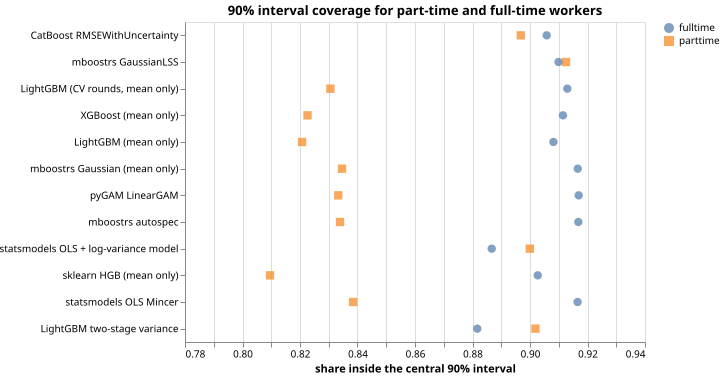

In [4]:
ORDER = ['CatBoost RMSEWithUncertainty', 'mboostrs GaussianLSS', 'LightGBM (CV rounds, mean only)', 'XGBoost (mean only)', 'LightGBM (mean only)', 'mboostrs Gaussian (mean only)', 'pyGAM LinearGAM', 'mboostrs autospec', 'statsmodels OLS + log-variance model', 'sklearn HGB (mean only)', 'statsmodels OLS Mincer', 'LightGBM two-stage variance']
groups = (scores.select("method", "coverage90_parttime", "coverage90_fulltime")
          .unpivot(index="method", variable_name="group", value_name="coverage")
          .with_columns(pl.col("group").str.replace("coverage90_", "")))
alt.Chart(groups).mark_point(filled=True, size=70).encode(
    x=alt.X("coverage:Q", scale=alt.Scale(domain=[0.78, 0.94]), title="share inside the central 90% interval"),
    y=alt.Y("method:N", sort=ORDER, title=None),
    color=alt.Color("group:N", title=None),
    shape=alt.Shape("group:N", title=None),
).properties(width=460, height=320, title="90% interval coverage for part-time and full-time workers")

In [5]:
ORDER_KEY = pl.col("method").replace_strict({'CatBoost RMSEWithUncertainty': 0, 'mboostrs GaussianLSS': 1, 'LightGBM (CV rounds, mean only)': 2, 'XGBoost (mean only)': 3, 'LightGBM (mean only)': 4, 'mboostrs Gaussian (mean only)': 5, 'pyGAM LinearGAM': 6, 'mboostrs autospec': 7, 'statsmodels OLS + log-variance model': 8, 'sklearn HGB (mean only)': 9, 'statsmodels OLS Mincer': 10, 'LightGBM two-stage variance': 11}, default=99)
fails = failures(runs)
display(table(
    fails if fails.height else pl.DataFrame({"method": ["(none)"], "seed": [None], "error": [""]}),
    stub="method", stubhead="Method",
    title="Failed fits", subtitle="Each unsuccessful (method, seed) with the first line of its error",
    notes=["A failed seed is excluded from that method's means and counted in its failed column."],
))

GT(_tbl_data=shape: (1, 3)
┌────────┬──────┬───────┐
│ method ┆ seed ┆ error │
│ ---    ┆ ---  ┆ ---   │
│ str    ┆ null ┆ str   │
╞════════╪══════╪═══════╡
│ (none) ┆ null ┆       │
└────────┴──────┴───────┘, _body=<great_tables._gt_data.Body object at 0x10d735460>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='seed', type=<ColInfoTypeEnum.default: 1>, column_label='seed', column_align='center', column_width=None), ColInfo(var='error', type=<ColInfoTypeEnum.default: 1>, column_label='error', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10d76bd10>, _spanners=Spanners([]), _heading=Heading(title='Failed fits', subtitle='Each unsuccessful (method, seed) with the first line of its error', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10d5d7320>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10bee2240>, _source_notes=["A failed seed is excluded from that method's means and counted in its failed column."], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10bee2270>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10d76a150>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_bottom_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_left_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_left_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_left_color=OptionsInfo(s

In [6]:
display(table(
    memory(bench).with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"),
    stub="method", stubhead="Method",
    title="Peak memory of one fit",
    subtitle="Fresh process, seed 0: VmHWM after the fit minus VmRSS before it",
    labels={"seconds": "s", "peak_rss_growth_mb": "Δ RSS MB", "status": "status"},
    better={"peak_rss_growth_mb": "min"}, formats={"seconds": 2, "peak_rss_growth_mb": 1},
    notes=["The high-water mark is reset after imports and data loading, so the figure is the "
           "fit's own growth. One probe per method; descriptive, not averaged."],
))

GT(_tbl_data=shape: (12, 4)
┌─────────────────────────────────┬───────────┬────────────────────┬─────────┐
│ method                          ┆ seconds   ┆ peak_rss_growth_mb ┆ status  │
│ ---                             ┆ ---       ┆ ---                ┆ ---     │
│ str                             ┆ f64       ┆ f64                ┆ str     │
╞═════════════════════════════════╪═══════════╪════════════════════╪═════════╡
│ CatBoost RMSEWithUncertainty    ┆ 1.096182  ┆ 18.757812          ┆ success │
│ mboostrs GaussianLSS            ┆ 4.178939  ┆ 149.269531         ┆ success │
│ LightGBM (CV rounds, mean only… ┆ 1.1756    ┆ 25.550781          ┆ success │
│ XGBoost (mean only)             ┆ 0.512836  ┆ 14.46875           ┆ success │
│ LightGBM (mean only)            ┆ 0.667805  ┆ 11.046875          ┆ success │
│ …                               ┆ …         ┆ …                  ┆ …       │
│ mboostrs autospec               ┆ 10.744457 ┆ 216.65625          ┆ success │
│ statsmodels OLS + log-variance… ┆ 0.018882  ┆ 14.167969          ┆ success │
│ sklearn HGB (mean only)         ┆ 1.184812  ┆ 8.3125             ┆ success │
│ statsmodels OLS Mincer          ┆ 0.014367  ┆ 11.347656          ┆ success │
│ LightGBM two-stage variance     ┆ 2.183177  ┆ 13.761719          ┆ success │
└─────────────────────────────────┴───────────┴────────────────────┴─────────┘, _body=<great_tables._gt_data.Body object at 0x10d5d7320>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None), ColInfo(var='peak_rss_growth_mb', type=<ColInfoTypeEnum.default: 1>, column_label='Δ RSS MB', column_align='right', column_width=None), ColInfo(var='status', type=<ColInfoTypeEnum.default: 1>, column_label='status', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10bee1d60>, _spanners=Spanners([]), _heading=Heading(title='Peak memory of one fit', subtitle='Fresh process, seed 0: VmHWM after the fit minus VmRSS before it', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10d76b110>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10d76a330>, _source_notes=["The high-water mark is reset after imports and data loading, so the figure is the fit's own growth. One probe per method; descriptive, not averaged."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10D76A360>, mask=None), grpname=None, colname='seconds', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10D76A360>, mask=None), grpname=None, colname='seconds', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10D76A360>, mask=None), grpname=None, colname='seconds', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10D76A360>, mask=None), grpname=None, colname='peak_rss_growth_mb', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10D76A360>, mask=None), grpname=None, colname='peak_rss_growth_mb', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10D76A360>, mask=None), grpname=None, colname='peak_rss_growth_mb', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10D76A360>, mask=None), grpname=None, colname='status', row

In [7]:
display(table(
    warnings_by_method(bench).with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"),
    stub="method", stubhead="Method",
    title="Warnings raised during the fits",
    subtitle="Distinct warning texts across all seeds, with one example",
    labels={"distinct_warnings": "distinct", "example": "example"},
    notes=["Methods that raised none are omitted."],
))
display(table(
    lines(bench).with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"),
    stub="method", stubhead="Method",
    title="Lines of code per method",
    subtitle="Statements in each method's function in benches/bench_public_tasks.py",
    labels={"lines": "lines"},
    notes=["Docstrings, comments and blank lines are not counted. Shared helpers are not "
           "counted either: the tree rows hide a settings helper (tree_model) and the CV-rounds "
           "row hides a 9-line lightgbm.cv wrapper. Treat this as a rough ergonomics signal."],
))

GT(_tbl_data=shape: (1, 3)
┌───────────────────┬───────────────────┬─────────────────────────────────┐
│ method            ┆ distinct_warnings ┆ example                         │
│ ---               ┆ ---               ┆ ---                             │
│ str               ┆ i64               ┆ str                             │
╞═══════════════════╪═══════════════════╪═════════════════════════════════╡
│ mboostrs autospec ┆ 5                 ┆ UserWarning: optimal mstop 187… │
└───────────────────┴───────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10d5d7320>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='distinct_warnings', type=<ColInfoTypeEnum.default: 1>, column_label='distinct', column_align='right', column_width=None), ColInfo(var='example', type=<ColInfoTypeEnum.default: 1>, column_label='example', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10c0a38c0>, _spanners=Spanners([]), _heading=Heading(title='Warnings raised during the fits', subtitle='Distinct warning texts across all seeds, with one example', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10d76b440>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10d76bb30>, _source_notes=['Methods that raised none are omitted.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10D70DC10>, mask=None), grpname=None, colname='distinct_warnings', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10D70DC10>, mask=None), grpname=None, colname='example', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x10d76ac30>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10d76ae40>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=O

GT(_tbl_data=shape: (12, 2)
┌─────────────────────────────────┬───────┐
│ method                          ┆ lines │
│ ---                             ┆ ---   │
│ str                             ┆ i64   │
╞═════════════════════════════════╪═══════╡
│ CatBoost RMSEWithUncertainty    ┆ 3     │
│ mboostrs GaussianLSS            ┆ 7     │
│ LightGBM (CV rounds, mean only… ┆ 5     │
│ XGBoost (mean only)             ┆ 3     │
│ LightGBM (mean only)            ┆ 3     │
│ …                               ┆ …     │
│ mboostrs autospec               ┆ 10    │
│ statsmodels OLS + log-variance… ┆ 10    │
│ sklearn HGB (mean only)         ┆ 3     │
│ statsmodels OLS Mincer          ┆ 10    │
│ LightGBM two-stage variance     ┆ 11    │
└─────────────────────────────────┴───────┘, _body=<great_tables._gt_data.Body object at 0x10d5d7320>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='lines', type=<ColInfoTypeEnum.default: 1>, column_label='lines', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10d618f80>, _spanners=Spanners([]), _heading=Heading(title='Lines of code per method', subtitle="Statements in each method's function in benches/bench_public_tasks.py", preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10d76b890>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10d769e80>, _source_notes=['Docstrings, comments and blank lines are not counted. Shared helpers are not counted either: the tree rows hide a settings helper (tree_model) and the CV-rounds row hides a 9-line lightgbm.cv wrapper. Treat this as a rough ergonomics signal.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10D76B050>, mask=None), grpname=None, colname='lines', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10D76B050>, mask=None), grpname=None, colname='lines', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10D76B050>, mask=None), grpname=None, colname='lines', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x10d76a270>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10d76bad0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_bord

## Reproduction

```bash
RAYON_NUM_THREADS=1 OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 MKL_NUM_THREADS=1 \
  python benches/bench_public_tasks.py --task distributional \
  --out docs/book/benchmarks/bench_public_distributional.json
```

The artifact records the source URL and sha256, the seeds, the tree settings, the thread environment, library versions, the runner's sha256, the commit and the machine. This page reads the artifact and refits nothing.